# Lecture 2 Hands-On: Queueing Models

This notebook accompanies Lecture 2. We revisit Markovian queues, implement simulators for M/M/1 and M/M/c, and explore a non-Markov queue (M/G/1 with lognormal service).

## Imports

In [1]:

import math
import itertools

import numpy as np
import pandas as pd
import simpy
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-darkgrid')
RNG = np.random.default_rng(2025)


---
## Part A — Birth–Death Refresher

Use this section to verify the analytical expressions for the stationary measure of a homogeneous birth-death process discussed in class.

In [10]:

def geometric_stationary(rho, n):
    return (1 - rho) * (rho ** n)

# Example: rho = 0.7
rho = 0.7
pi = np.array([geometric_stationary(rho, n) for n in range(10)])
pi.sum()


np.float64(0.9717524750999998)

### Task A1
Compute $L, L_q, W, W_q$ for $(\lambda, \mu) = (4, 6)$ using the formulas from lecture. Then cross-check with Little's Law ($L = \lambda W$, $L_q = \lambda W_q$).

In [11]:

lam, mu = 4.0, 6.0
rho = lam / mu
L_formula = rho / (1 - rho)
Lq_formula = (rho**2) / (1 - rho)
W_formula = 1 / (mu - lam)
Wq_formula = rho / (mu - lam)

{
    'rho': rho,
    'L': L_formula,
    'L_q': Lq_formula,
    'W': W_formula,
    'W_q': Wq_formula,
    'Little_L': lam * W_formula,
    'Little_Lq': lam * Wq_formula,
}


{'rho': 0.6666666666666666,
 'L': 1.9999999999999998,
 'L_q': 1.333333333333333,
 'W': 0.5,
 'W_q': 0.3333333333333333,
 'Little_L': 2.0,
 'Little_Lq': 1.3333333333333333}

---
## Part B — Plain-Python Simulation of M/M/c

We extend the Part 1 simulator to $c$ servers. Below is a plain-Python discrete-event simulator that assigns each arrival to the server that becomes free the earliest (FCFS with $c$ identical servers).

In [12]:

def simulate_mmc_basic(lambda_rate, mu_rate, servers, sim_hours, rng, max_events=10_000):
    arrival_times = []
    service_start_times = []
    departure_times = []
    waiting_times = []
    system_times = []

    current_time = 0.0
    server_available_times = [0.0] * servers
    event_count = 0

    while current_time < sim_hours and event_count < max_events:
        inter_arrival = rng.exponential(1 / lambda_rate)
        current_time += inter_arrival
        if current_time > sim_hours:
            break

        arrival_times.append(current_time)

        # Choose the server that becomes free the earliest (FCFS across servers)
        server_idx = int(np.argmin(server_available_times))
        earliest_completion = server_available_times[server_idx]

        service_time = rng.exponential(1 / mu_rate)
        start_time = max(current_time, earliest_completion)
        finish_time = start_time + service_time

        server_available_times[server_idx] = finish_time

        service_start_times.append(start_time)
        departure_times.append(finish_time)
        waiting_times.append(start_time - current_time)
        system_times.append(finish_time - current_time)

        event_count += 1

    return {
        'arrivals': np.array(arrival_times),
        'starts': np.array(service_start_times),
        'departures': np.array(departure_times),
        'waiting_times': np.array(waiting_times),
        'system_times': np.array(system_times),
    }

# Choose parameters (run long enough to reach steady behaviour)
lam_mm2, mu_mm2, servers = 8.0, 5.0, 2
logs_mmc = simulate_mmc_basic(lam_mm2, mu_mm2, servers, sim_hours=2000.0, rng=RNG)
print(f"Simulated {len(logs_mmc['arrivals'])} arrivals.")

Simulated 10000 arrivals.


### Task B1
Validate the simulation by comparing empirical means with the Erlang-C predictions ($P_{wait}$, $L_q$, $W_q$). Provide a short discussion on discrepancies and simulation length.

In [13]:

def erlang_c(lambda_rate, mu_rate, servers):
    rho = lambda_rate / (servers * mu_rate)
    if rho >= 1:
        raise ValueError('System is unstable (rho >= 1).')
    terms = [((servers * rho) ** k) / math.factorial(k) for k in range(servers)]
    numerator = ((servers * rho) ** servers) / math.factorial(servers) * (1 / (1 - rho))
    denominator = sum(terms) + numerator
    P_wait = numerator / denominator
    L_q = P_wait * (rho / (1 - rho))
    W_q = L_q / lambda_rate
    W = W_q + 1 / mu_rate
    L = L_q + (lambda_rate / mu_rate)
    return {'rho': rho, 'P_wait': P_wait, 'L_q': L_q, 'L': L, 'W_q': W_q, 'W': W}


In [14]:

theory_mmc = erlang_c(lam_mm2, mu_mm2, servers)
waiting_emp = logs_mmc['waiting_times']
system_emp = logs_mmc['system_times']

comparison = {
    'rho': theory_mmc['rho'],
    'P_wait_theory': theory_mmc['P_wait'],
    'P_wait_emp': float((waiting_emp > 1e-12).mean()),
    'W_q_theory': theory_mmc['W_q'],
    'W_q_emp': float(waiting_emp.mean()),
    'W_theory': theory_mmc['W'],
    'W_emp': float(system_emp.mean()),
}
comparison


{'rho': 0.8,
 'P_wait_theory': 0.7111111111111112,
 'P_wait_emp': 0.7205,
 'W_q_theory': 0.3555555555555557,
 'W_q_emp': 0.35353223295671926,
 'W_theory': 0.5555555555555557,
 'W_emp': 0.5512409029539056}

---
## Part C — SimPy M/M/c

Build on the primer from Lecture 1: we now use a `simpy.Resource(capacity=c)` to model $c$ servers and reproduce the M/M/$c$ queue.

### SimPy M/M/c Implementation
We now implement an M/M/c queue using SimPy's `Resource(capacity=c)`, aligned with the primer from Lecture 1. We log arrivals, service starts, and departures to compute waiting/sojourn times and compare to Erlang-C.

In [15]:

def simulate_mmc_simpy(lambda_rate, mu_rate, servers, duration_hours, rng, max_customers=100_000):
    env = simpy.Environment()
    server = simpy.Resource(env, capacity=servers)

    arrivals, starts, departures = [], [], []

    def customer(env, cust_id):
        t_arr = env.now
        arrivals.append(t_arr)
        with server.request() as req:
            yield req
            t_start = env.now
            starts.append(t_start)
            svc = rng.exponential(1 / mu_rate)
            yield env.timeout(svc)
            departures.append(env.now)

    def arrival_generator(env):
        for cust_id in itertools.count(1):
            inter = rng.exponential(1 / lambda_rate)
            yield env.timeout(inter)
            if env.now > duration_hours or cust_id > max_customers:
                break
            env.process(customer(env, cust_id))

    env.process(arrival_generator(env))
    env.run()

    a = np.array(arrivals)
    s = np.array(starts)
    d = np.array(departures)
    m = min(a.size, s.size, d.size)
    a, s, d = a[:m], s[:m], d[:m]  # align lengths

    return {
        'arrivals': a,
        'starts': s,
        'departures': d,
        'waiting_times': s - a,
        'system_times': d - a,
    }

# Example run and comparison
lam_c, mu_c, c_servers = 8.0, 5.0, 2
sim_hours = 200.0
logs_c = simulate_mmc_simpy(lam_c, mu_c, c_servers, sim_hours, RNG)
theory_c = erlang_c(lam_c, mu_c, c_servers)

wait = logs_c['waiting_times']
sys_t = logs_c['system_times']
a, d = logs_c['arrivals'], logs_c['departures']
m = a.size
front = int(0.1 * m) if m >= 200 else 0
back = int(0.05 * m) if m >= 200 else 0
if front or back:
    sl = slice(front, m - back if back else None)
    a, d = a[sl], d[sl]
    wait, sys_t = wait[sl], sys_t[sl]
lam_hat = (d.size - 1) / (d[-1] - d[0]) if d.size > 1 else np.nan

rho_emp = lam_hat / (c_servers * mu_c) if np.isfinite(lam_hat) else np.nan
L_q_emp = float(lam_hat * wait.mean()) if np.isfinite(lam_hat) else np.nan
L_emp = float(lam_hat * sys_t.mean()) if np.isfinite(lam_hat) else np.nan

results_c = {
    'rho_theory': theory_c['rho'],
    'rho_emp': rho_emp,
    'P_wait_theory': theory_c['P_wait'],
    'P_wait_emp': float((wait > 1e-12).mean()),
    'W_q_theory': theory_c['W_q'],
    'W_q_emp': float(wait.mean()),
    'W_theory': theory_c['W'],
    'W_emp': float(sys_t.mean()),
    'L_q_theory': theory_c['L_q'],
    'L_q_emp': L_q_emp,
    'L_theory': theory_c['L'],
    'L_emp': L_emp,
}
results_c


{'rho_theory': 0.8,
 'rho_emp': np.float64(0.7912238617995494),
 'P_wait_theory': 0.7111111111111112,
 'P_wait_emp': 0.7154592979835698,
 'W_q_theory': 0.3555555555555557,
 'W_q_emp': 0.38168326567391003,
 'W_theory': 0.5555555555555557,
 'W_emp': 0.5842670433618034,
 'L_q_theory': 2.8444444444444454,
 'L_q_emp': 3.019969074507745,
 'L_theory': 4.4444444444444455,
 'L_emp': 4.622860263709309}

---
## Part D — Non-Markov Queue (M/G/1 with Lognormal Service)

We consider an M/G/1 queue where service times are lognormally distributed (mean $1/\mu$, variance controlled by $\sigma$). This breaks the memoryless assumption and highlights the impact of variability.

In [16]:

def simulate_mg1_lognormal(lambda_rate, service_mean, service_sigma, duration_hours, rng):
    env = simpy.Environment()
    server = simpy.Resource(env, capacity=1)

    arrivals, starts, departures = [], [], []

    def service_time():
        mu_log = math.log(service_mean) - 0.5 * service_sigma ** 2
        return math.exp(mu_log + service_sigma * rng.normal())

    def customer(env, cust_id):
        arrival = env.now
        arrivals.append(arrival)
        with server.request() as req:
            yield req
            start = env.now
            starts.append(start)
            yield env.timeout(service_time())
            departures.append(env.now)

    def generator(env):
        cust_id = 0
        while True:
            inter = rng.exponential(1 / lambda_rate)
            yield env.timeout(inter)
            cust_id += 1
            if env.now > duration_hours:
                break
            env.process(customer(env, cust_id))

    env.process(generator(env))
    env.run(until=duration_hours)

    return {
        'arrivals': np.array(arrivals),
        'starts': np.array(starts),
        'departures': np.array(departures),
    }


### Task D1
Run the simulator for several hours with $\lambda = 4$, service mean $1/5$, and lognormal shape parameter $\sigma = 0.6$. Compute empirical waiting times and compare the mean to the Pollaczek–Khinchine prediction.

In [32]:

lambda_mg1 = 4.0
service_mean = 1 / 5.0
service_sigma = 0.6
duration = 400.0
logs_mg1 = simulate_mg1_lognormal(lambda_mg1, service_mean, service_sigma, duration, RNG)

m = min(logs_mg1['starts'].size, logs_mg1['arrivals'].size, logs_mg1['departures'].size,logs_mg1['arrivals'].size)

waiting_mg1 = logs_mg1['starts'][:m] - logs_mg1['arrivals'][:m]
system_mg1 = logs_mg1['departures'][:m] - logs_mg1['arrivals'][:m]

mean_wait_emp = waiting_mg1.mean()
var_service = (math.exp(service_sigma ** 2) - 1) * (service_mean ** 2)
second_moment_service = var_service + service_mean ** 2
rho_mg1 = lambda_mg1 * service_mean
Wq_pk = (lambda_mg1 * second_moment_service) / (2 * (1 - rho_mg1))
W_pk = Wq_pk + service_mean

{
    'rho': rho_mg1,
    'empirical_wait_mean': mean_wait_emp,
    'PK_wait_mean': Wq_pk,
    'empirical_sojourn_mean': system_mg1.mean(),
    'PK_sojourn_mean': W_pk,
}


{'rho': 0.8,
 'empirical_wait_mean': np.float64(0.6346840317511577),
 'PK_wait_mean': 0.5733317658241363,
 'empirical_sojourn_mean': np.float64(0.8311850794970779),
 'PK_sojourn_mean': 0.7733317658241363}

### Task D2
Produce plots illustrating the difference between exponential and lognormal services:
- Histogram (or KDE) of waiting times for exponential vs. lognormal service under the same arrival rate.
- Running time-average of waiting times to assess convergence.
- Empirical tail probability $\mathbb{P}(W_q > t)$ vs. $t$, compared with exponential-case prediction.

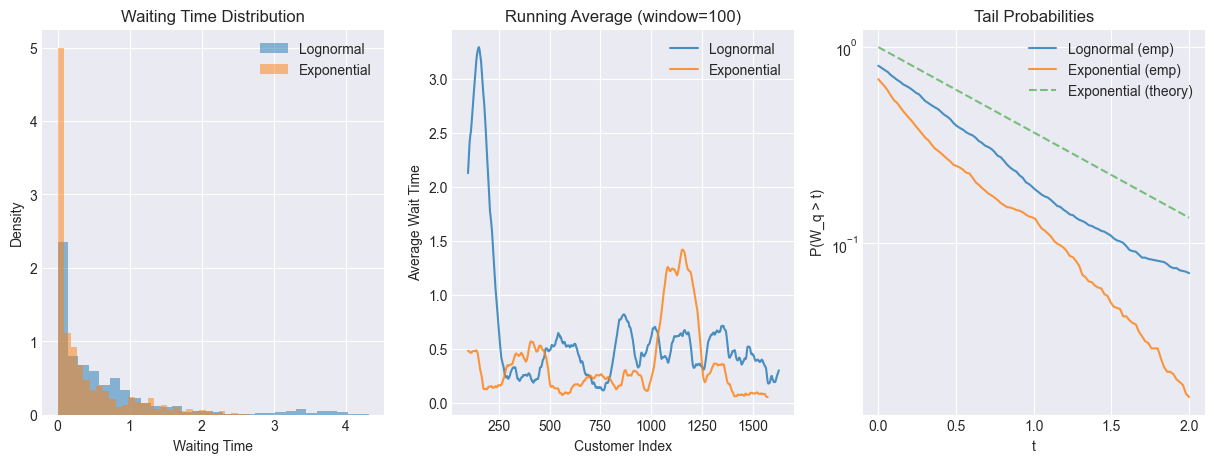

In [33]:
# Create comparison plots between exponential and lognormal services
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

# 1. Histogram/KDE of waiting times
ax1.hist(waiting_mg1, bins=30, density=True, alpha=0.5, label='Lognormal')
exp_wait = logs_c['waiting_times']
ax1.hist(exp_wait, bins=30, density=True, alpha=0.5, label='Exponential')
ax1.set_xlabel('Waiting Time')
ax1.set_ylabel('Density')
ax1.set_title('Waiting Time Distribution')
ax1.legend()

# 2. Running average of waiting times
window = 100
mg1_running = pd.Series(waiting_mg1).rolling(window=window).mean()
exp_running = pd.Series(exp_wait).rolling(window=window).mean()
ax2.plot(mg1_running, label='Lognormal', alpha=0.8)
ax2.plot(exp_running, label='Exponential', alpha=0.8)
ax2.set_xlabel('Customer Index')
ax2.set_ylabel('Average Wait Time')
ax2.set_title(f'Running Average (window={window})')
ax2.legend()

# 3. Tail probability P(W_q > t)
t_vals = np.linspace(0, 2, 100)
p_mg1 = [np.mean(waiting_mg1 > t) for t in t_vals]
p_exp = [np.mean(exp_wait > t) for t in t_vals]
# Theoretical exponential tail for M/M/c
rho = lambda_mg1 / mu_c
theoretical = np.exp(-t_vals * (mu_c - lambda_mg1))

ax3.plot(t_vals, p_mg1, label='Lognormal (emp)', alpha=0.8)
ax3.plot(t_vals, p_exp, label='Exponential (emp)', alpha=0.8)
ax3.plot(t_vals, theoretical, '--', label='Exponential (theory)', alpha=0.6)
ax3.set_yscale('log')
ax3.set_xlabel('t')
ax3.set_ylabel('P(W_q > t)')
ax3.set_title('Tail Probabilities')
ax3.legend()

%matplotlib inline


### Task D3
Quantitative bounds: for $N$ samples of waiting time, derive a confidence interval for the mean using either CLT or Bernstein-style inequality. Compare the width of the interval for exponential vs. lognormal services.

In [28]:
from scipy import stats

# Confidence interval using CLT
def confidence_interval_clt(data, confidence=0.95):
    mean = np.mean(data)
    std_err = stats.sem(data)
    interval = std_err * stats.t.ppf((1 + confidence) / 2, len(data) - 1)
    return mean - interval, mean + interval, 2 * interval  # lower, upper, width


# Confidence interval using Bernstein inequality
def confidence_interval_bernstein(data, confidence=0.95):
    mean = np.mean(data)
    variance = np.var(data)
    n = len(data)
    z = stats.norm.ppf((1 + confidence) / 2)
    delta = np.sqrt((2 * variance * z**2) / n + (2 * z * np.max(np.abs(data - mean))) ** 2 / (3 * n))
    return mean - delta, mean + delta, 2 * delta  # lower, upper, width


# Apply CLT
clt_exp_lower, clt_exp_upper, clt_exp_width = confidence_interval_clt(exp_wait)
clt_lognormal_lower, clt_lognormal_upper, clt_lognormal_width = confidence_interval_clt(waiting_mg1)

# Apply Bernstein
bernstein_exp_lower, bernstein_exp_upper, bernstein_exp_width = confidence_interval_bernstein(exp_wait)
bernstein_lognormal_lower, bernstein_lognormal_upper, bernstein_lognormal_width = confidence_interval_bernstein(waiting_mg1)

print("CLT Confidence Intervals:")
print(f"Exponential: ({clt_exp_lower:.4f}, {clt_exp_upper:.4f}), width: {clt_exp_width:.4f}")
print(f"Lognormal: ({clt_lognormal_lower:.4f}, {clt_lognormal_upper:.4f}), width: {clt_lognormal_width:.4f}")

print("\nBernstein Confidence Intervals:")
print(f"Exponential: ({bernstein_exp_lower:.4f}, {bernstein_exp_upper:.4f}), width: {bernstein_exp_width:.4f}")
print(f"Lognormal: ({bernstein_lognormal_lower:.4f}, {bernstein_lognormal_upper:.4f}), width: {bernstein_lognormal_width:.4f}")

CLT Confidence Intervals:
Exponential: (0.3342, 0.3846), width: 0.0504
Lognormal: (0.4482, 0.5442), width: 0.0960

Bernstein Confidence Intervals:
Exponential: (0.2224, 0.4964), width: 0.2740
Lognormal: (0.3022, 0.6903), width: 0.3881


---
## Part E — To Explore Further

- Extend the M/G/1 example to a GI/G/1 queue with Erlang inter-arrivals; observe how burstiness affects $W_q$.
- Implement regenerative confidence intervals (batch means) to reduce bias.
- Try a heavy-tailed service time (Pareto) and examine the empirical tail behaviour.